# **Predicting Slow Bus Segments with Machine Learning using New York MTA Bus Route Segments Dataset**

**Research Questions**:
1. Did buses inside the zone get faster than buses elsewhere after the implementaion of congestion pricing?
2. Can machine learning models predict where and when buses are slow, even on routes it has never seen?

**Data**: MTA Bus Route Segment Speeds, October–December 2024 (before) and October–December 2025 (after), from New York State Open Data.

**Models**: Logistic Regression, Decision Tree, Random Forest

**The notebook is divided into 5 parts**

Part A: Preparing the data

Part B: Exploring the data

Part C: RQ1, does the toll explain where and when buses got faster?

Part D: RQ2, predicting slow segments

Part E: Bus Priority List

#**Part A: Preparing the data**
1. Setup and loading
2. Dropping columns we don't need
3. Cleaning rows
4. Creating new features

**Part A1. Setup and Load the Data - Obtain Phase**




In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [49]:
#Loading files

file_2024 = pd.read_csv("MTA_Bus_Route_Segment_Speeds__2023_-_2024_20260927.csv")    # Oct-Dec 2024
file_2025 = pd.read_csv("MTA_Bus_Route_Segment_Speeds__Beginning_2025_20260927.csv") # Oct-Dec 2025

In [50]:
print("2024 shape: ",file_2024.shape)
print("2025 shape: ",file_2025.shape)
print("Same columns in both files: ",file_2024.columns.tolist() == file_2025.columns.tolist())

2024 shape:  (1437519, 24)
2025 shape:  (1425421, 24)
Same columns in both files:  True


In [51]:
print(file_2025.columns.tolist())

['Year', 'Month', 'Timestamp', 'Day of Week', 'Hour of Day', 'Route ID', 'Direction', 'Borough', 'Route Type', 'Stop Order', 'Timepoint Stop ID', 'Timepoint Stop Name', 'Timepoint Stop Latitude', 'Timepoint Stop Longitude', 'Next Timepoint Stop ID', 'Next Timepoint Stop Name', 'Next Timepoint Stop Latitude', 'Next Timepoint Stop Longitude', 'Road Distance', 'Average Travel Time', 'Average Road Speed', 'Bus Trip Count', 'Timepoint Stop Georeference', 'Next Timepoint Stop Georeference']


In [52]:
file_2025.head()

,Year,Month,Timestamp,Day of Week,Hour of Day,Route ID,Direction,Borough,Route Type,Stop Order,...,Next Timepoint Stop ID,Next Timepoint Stop Name,Next Timepoint Stop Latitude,Next Timepoint Stop Longitude,Road Distance,Average Travel Time,Average Road Speed,Bus Trip Count,Timepoint Stop Georeference,Next Timepoint Stop Georeference
0,2025,11,2025 Nov 01 12:00:00 AM,Tuesday,0,B25,E,Brooklyn,Local,9,...,302947,FULTON ST/BOND ST,40.689709,-73.983099,0.706,5.472228,7.740903,6,POINT (-73.990366 40.696104),POINT (-73.983099 40.689709)
1,2025,11,2025 Nov 01 03:00:00 AM,Tuesday,3,B25,E,Brooklyn,Local,9,...,302947,FULTON ST/BOND ST,40.689709,-73.983099,0.706,6.294462,6.729727,3,POINT (-73.990366 40.696104),POINT (-73.983099 40.689709)
2,2025,11,2025 Nov 01 03:00:00 PM,Tuesday,15,B25,E,Brooklyn,Local,9,...,302947,FULTON ST/BOND ST,40.689709,-73.983099,0.706,10.561734,4.010706,27,POINT (-73.990366 40.696104),POINT (-73.983099 40.689709)
3,2025,11,2025 Nov 01 06:00:00 AM,Tuesday,6,B36,W,Brooklyn,Local,25,...,901058,SURF AV/W 37 ST,40.573237,-74.002018,1.164,7.179708,9.727413,23,POINT (-73.981204 40.575581),POINT (-74.002018 40.573237)
4,2025,11,2025 Nov 01 03:00:00 AM,Tuesday,3,B38,E,Brooklyn,Local,1,...,302947,FULTON ST/BOND ST,40.689709,-73.983099,0.705,5.141670,8.226899,4,POINT (-73.990366 40.696104),POINT (-73.983099 40.689709)


Each row is **one stretch of a bus route** (between two major stops, called *timepoints*), for one **month**, **day of the week** and **hour**. It tells us how fast buses travelled on that stretch, on average.

**Part A2. Drop unnecessary columns - Scrub Phase**


**Columns dropped and why**

- **Timestamp**: only a placeholder (the 1st of the month plus the hour), and its weekday is **wrong**. For example, "2025 Nov 01" shows "Tuesday", but 1 Nov 2025 was a Saturday. We use Day of Week, Month and Hour of Day instead.
- **Timepoint Stop Georeference** and **Next Timepoint Stop Georeference**: these repeat the latitude and longitude as text, which the numeric columns already hold.
- **Average Travel Time**: speed = distance ÷ travel time, so keeping it would give the answer away (**data leakage**).
- **Stop Order**: the position of a stop along its route. Stop number 9 on one route has nothing in common with stop 9 on another, so it isn't a meaningful input.

In [53]:
drop_columns = ["Timestamp",
    "Timepoint Stop Georeference",
    "Next Timepoint Stop Georeference",
    "Average Travel Time",
    "Stop Order"]

file_2024 = file_2024.drop(columns=drop_columns)
file_2025 = file_2025.drop(columns=drop_columns)

ny_bus = pd.concat([file_2024,file_2025], ignore_index=True)

print("Combines rows: ", len(ny_bus))
print("Columns kept: ", ny_bus.columns.tolist())

Combines rows:  2862940
Columns kept:  ['Year', 'Month', 'Day of Week', 'Hour of Day', 'Route ID', 'Direction', 'Borough', 'Route Type', 'Timepoint Stop ID', 'Timepoint Stop Name', 'Timepoint Stop Latitude', 'Timepoint Stop Longitude', 'Next Timepoint Stop ID', 'Next Timepoint Stop Name', 'Next Timepoint Stop Latitude', 'Next Timepoint Stop Longitude', 'Road Distance', 'Average Road Speed', 'Bus Trip Count']


**Part A3. Cleaning rows - Scrub Phase**

Cleaning rows with missing data, incorrect values, school bus routes and routes with less than 4 trips

In [54]:
#cleaning_log records how many rows each step removes

cleaning_log = [("Combined Data", len(ny_bus))]

ny_bus= ny_bus.dropna(subset=["Timepoint Stop Latitude", "Next Timepoint Stop Latitude"])
cleaning_log.append(("Missing coordinates removed", len(ny_bus)))

min_trips = 5
ny_bus = ny_bus[ny_bus["Bus Trip Count"] >= min_trips]
cleaning_log.append((f"Fewer than {min_trips} trips removed", len(ny_bus)))

ny_bus = ny_bus[(ny_bus["Average Road Speed"] > 0.5) & (ny_bus["Average Road Speed"] < 40) & (ny_bus["Road Distance"] > 0.05)]
cleaning_log.append(("Error values removed", len(ny_bus)))

ny_bus = ny_bus[~ny_bus["Route Type"].str.startswith("School")]
cleaning_log.append(("School routes removed", len(ny_bus)))

cleaning_log = pd.DataFrame(cleaning_log, columns=["Scrubbing steps", "rows_left"])
cleaning_log["rows_removed"] = -cleaning_log["rows_left"].diff().fillna(0).astype(int)
cleaning_log

,Scrubbing steps,rows_left,rows_removed
0,Combined Data,2862940,0
1,Missing coordinates removed,2858338,4602
2,Fewer than 5 trips removed,2536224,322114
3,Error values removed,2532771,3453
4,School routes removed,2517382,15389


**Part A4. Creating new features**

**Congestion Pricing Zone Segration** - The congestion pricing zone (Manhattan below 60th street) needs to be extracted from the data. This done by drawing an approximate outline of the area and checking which bus stops fall inside the zone.

In [55]:
from matplotlib.path import Path  #tool for drawing a shape and testing which points fall inside it

#Outline of the Congetsion Relief Zone and each point is (longitude, latitude)
#Starting at the southern tip, up to West side, across 60th street, and down to East side
zone_outline = Path([
    #West side going north along the Hudson river
     (-74.0170, 40.7005), (-74.0190, 40.7060), (-74.0140, 40.7250), (-74.0100, 40.7400),(-74.0020, 40.7600), (-73.9930, 40.7730),
     #North across 60th street to the other side
     (-73.9580, 40.7590),
    #East side going along East River
     (-73.9710, 40.7430),(-73.9730, 40.7270), (-73.9770, 40.7100), (-73.9990, 40.7080), (-74.0120, 40.7010),
])

**New features**

- **inside_zone**: 1 if **both** stops of a segment are inside the Congestion Relief Zone, otherwise 0. The zone isn't marked in the data, so each stop is checked against the zone outline.
- **boundary**: 1 if **exactly one** stop is inside the zone, meaning the segment crosses the zone's edge. These segments are only partly affected by the toll, so they are left out of RQ1.
- **after**: 1 for 2025 (after congestion pricing started), 0 for 2024.
- **inside_after**: 1 only for segments inside the zone **and** in 2025, the rows that pricing could directly affect.
- **weekend**: 1 for Saturday or Sunday, 0 for weekdays.
- **full_toll**: 1 during full-toll hours (weekdays 5 a.m-9 p.m., weekends 9 a.m.-9 p.m.), when cars pay 9 dollars instead of 2.25 dollars. Used to test whether gains were bigger when the toll was highest.
- **mid_lat**, **mid_lon**: the halfway point of each segment, so the models know **where** it is.
- **area**: which of four groups the segment belongs to: Inside zone, Boundary, Manhattan outside zone, or Other boroughs. Used to compare speed changes between areas in RQ1.

In [56]:
#Check each bus stop against the zone outline
#For every row, check of the "Start" stop is inside the zone
start_inside = zone_outline.contains_points(ny_bus[["Timepoint Stop Longitude", "Timepoint Stop Latitude"]].values)
#For every row, check of the "End" stop is inside the zone
end_inside = zone_outline.contains_points(ny_bus[["Next Timepoint Stop Longitude", "Next Timepoint Stop Latitude"]].values)

#Create new columns
#if both stops are inside the zone
ny_bus["inside_zone"] = (start_inside & end_inside).astype(int)

# if exactly one of the two stops is inside (the segment crosses the zone's edge)
ny_bus["boundary"] = (start_inside != end_inside).astype(int)

#1 if the row is for the year 2025 (after congestion pricing started), 0 if 2024
ny_bus["after"] = (ny_bus["Year"] ==2025).astype(int)

#Rows directly affected by congestion pricing - segments inside the zone and from 2025
ny_bus["inside_after"] = ny_bus["inside_zone"] * ny_bus["after"]

#weekend = 1 and weekday = 0
ny_bus["weekend"] = ny_bus["Day of Week"].isin(["Saturday", "Sunday"]).astype(int)

# full_toll = 1 during full-toll hours (weekdays hours 5-20, weekends hours 9-20)
weekday_full = (ny_bus["weekend"] == 0) & (ny_bus["Hour of Day"] >= 5) & (ny_bus["Hour of Day"] <= 20)
weekend_full = (ny_bus["weekend"] == 1) & (ny_bus["Hour of Day"] >= 9) & (ny_bus["Hour of Day"] <= 20)
ny_bus["full_toll"] = (weekday_full | weekend_full).astype(int)


#mid_lat = halfway point between the two stop' latitude
ny_bus["mid_lat"] = (ny_bus["Timepoint Stop Latitude"] + ny_bus["Next Timepoint Stop Latitude"])/2
#mid_lon = halfway point between the two stop's longitudes
ny_bus["mid_lon"] = (ny_bus["Timepoint Stop Longitude"] + ny_bus["Next Timepoint Stop Longitude"])/2

# area = which of four groups the segment belongs to
ny_bus["area"] = "Other boroughs"
ny_bus.loc[ny_bus["Borough"] == "Manhattan", "area"] = "Manhattan outside zone"
ny_bus.loc[ny_bus["boundary"] == 1, "area"] = "Boundary"
ny_bus.loc[ny_bus["inside_zone"] == 1, "area"] = "Inside zone"

#Total rows inside the zone
print("Rows inside the zone:", ny_bus["inside_zone"].sum())
#Total different routes with segments inside the zone
print("Routes with segments inside the zone:", ny_bus.loc[ny_bus["inside_zone"]==1, "Route ID"].nunique())
#Total rows with full-toll hours
print("Share of rows in full-toll hours:", round(ny_bus["full_toll"].mean() * 100, 1), "%")
print(ny_bus["area"].value_counts())

Rows inside the zone: 198785
Routes with segments inside the zone: 113
Share of rows in full-toll hours: 74.3 %
area
Other boroughs            2057419
Inside zone                198785
Manhattan outside zone     186823
Boundary                    74355
Name: count, dtype: int64


#**Part B: Exploring the data**

B1. Check the zone on a map

B2. Bus speed change through the day

B3. Correlation heatmap

**Part B1. Check the zone on a map.**

Red points should cover Manhattan below 60th Street only.

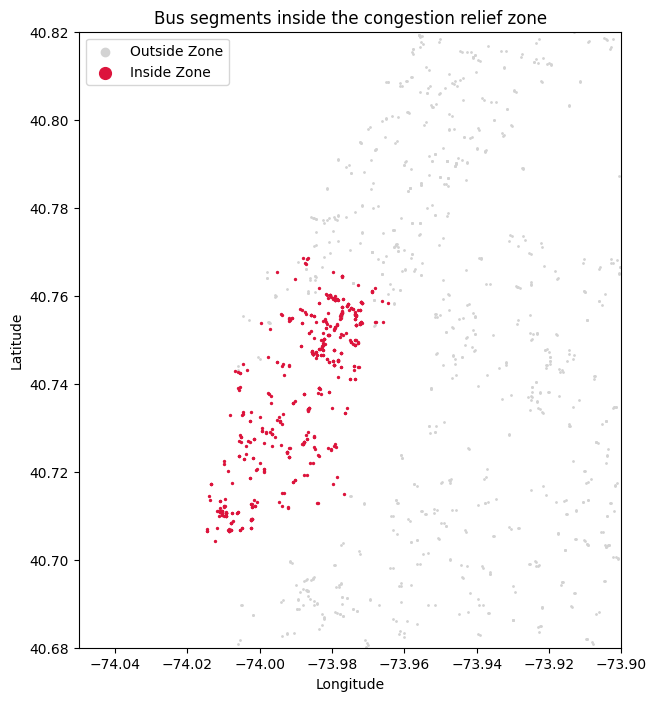

In [57]:
segments = ny_bus.drop_duplicates(subset=["Route ID", "Timepoint Stop ID", "Next Timepoint Stop ID"])

plt.figure(figsize=(7,8))
outside = segments[segments["inside_zone"] == 0]
inside = segments[segments["inside_zone"] == 1]
plt.scatter(outside["mid_lon"],outside["mid_lat"], s=1, color = "lightgray", label = "Outside Zone")
plt.scatter(inside["mid_lon"],inside["mid_lat"], s=2, color = "crimson", label = "Inside Zone")
plt.xlim(-74.05, -73.90)
plt.ylim(40.68, 40.82)
plt.title("Bus segments inside the congestion relief zone")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=6)
plt.savefig("fig1_Bus_segments_inside_zone.png", dpi=300, bbox_inches="tight")
plt.show()


**Part B2. Bus speed change through the day Exploring the data - Explore Phase**

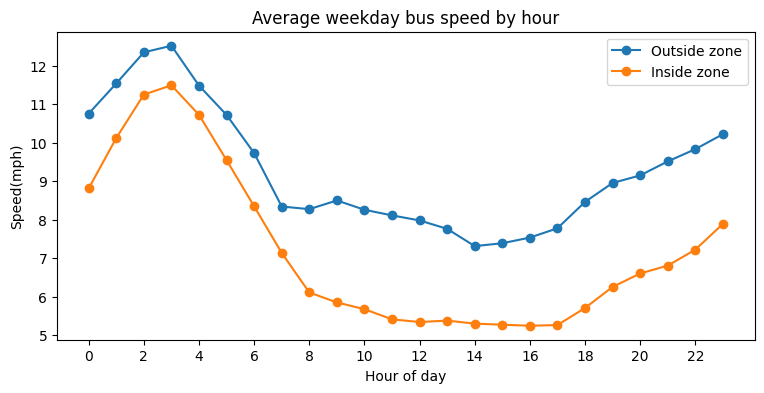

In [58]:
hourly = ny_bus[ny_bus["weekend"] == 0].groupby(["Hour of Day", "inside_zone"])["Average Road Speed"].mean().unstack()
hourly.columns = ["Outside zone", "Inside zone"]

hourly.plot(figsize=(9,4), marker="o")
plt.title("Average weekday bus speed by hour")
plt.xlabel("Hour of day")
plt.ylabel("Speed(mph)")
plt.xticks(range(0,24,2))
plt.savefig("fig2_Average_weekday_bus_speedbyhour.png", dpi=300, bbox_inches="tight")
plt.show()


**Part B3. Correlation heatmap - Explore Phase**

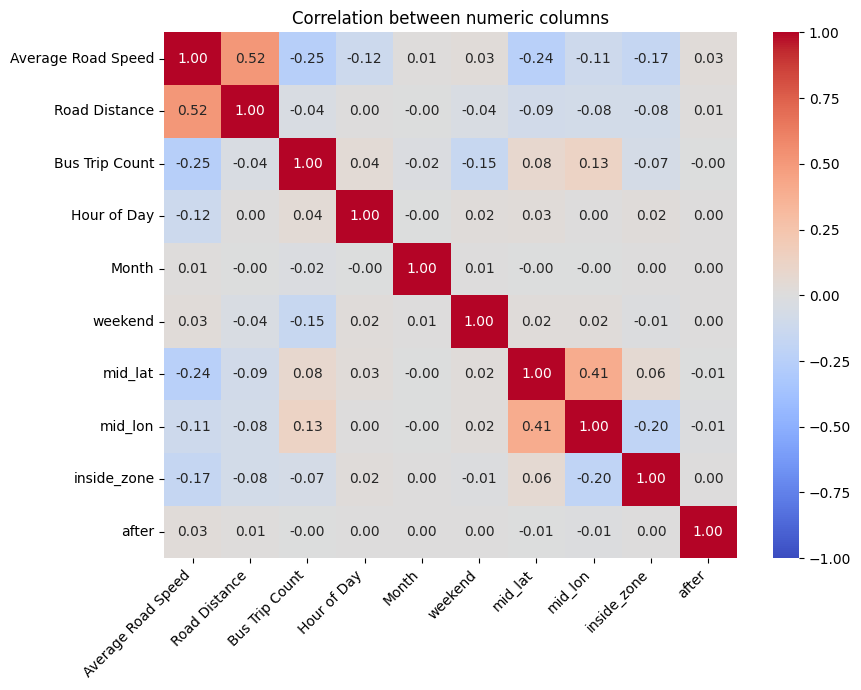

In [59]:
import seaborn as sns

heatmap_columns = ["Average Road Speed", "Road Distance", "Bus Trip Count", "Hour of Day", "Month",
                   "weekend", "mid_lat", "mid_lon", "inside_zone", "after"]
corr = ny_bus[heatmap_columns].sample(200_000, random_state=42).corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr,annot=True,fmt=".2f", cmap="coolwarm",vmin=-1,vmax=1,)

plt.title("Correlation between numeric columns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("fig3_Correlation.png", dpi=300, bbox_inches="tight")
plt.show()


**Reading the heatmap**


*   Road distance has the strongest link with speed(+0.52)Longer segments mean fewer stops per mile, so buses spend more time moving and less time stopping.
*   Bus trip count is negative (-0.25) Segments served by many buses are in dense areas with heavy traffic and crowded stops, exactly where bus priority matters most.
*   Location matters -0.24 with *mid_lat*, -0.17 with *inside_zone*. Segments further north and inside the zone tend to be slower, reflecting Manhattan's and the Bronx's dense street grids.
*   Time of day looks weak(-0.12), but misleading. Speeds fall through the morning and stay low until the evening (see the hourly chart above), a pattern a single straight-line number can't capture. This is one reason non-linear models are needed.
*   The policy period barely moves speed (+0.03 with *after*). On its own, being in 2025 rather than 2024 makes almost no difference.

**Implications for modelling:** no two inputs are strongly correlated with each other (the highest is latitude and longitude, +0.41), so all inputs can be kept.








#**Part C: RQ1, does the toll explain where and when buses got faster?**

C1. Comparing speed between 2024 and 2025

C2. Speed change for different bus type

**Part C1. Comparing speed between 2024 and 2025 - Explore Phase**

Each segment is comapared along the same route, stops, month, weekday and hour in 2024 and 2025. Roads with more buses count more in the average, because they affect more passengers

In [60]:
#the columns that must match in both years for comparison
match_on = ["Route ID", "Direction", "Timepoint Stop ID", "Next Timepoint Stop ID",
            "Month", "Day of Week", "Hour of Day"]
#Splitting the data into two years
rows_2024 = ny_bus[ny_bus["after"] == 0]
rows_2025 = ny_bus[ny_bus["after"] == 1]

#Keeping only the columns needed from each years
rows_2024 = rows_2024[match_on + ["area", "full_toll", "Route Type", "Average Road Speed", "Bus Trip Count"]]
rows_2025 = rows_2025[match_on + ["Average Road Speed", "Bus Trip Count"]]

#Rename the speed and trip columns
rows_2024 = rows_2024.rename(columns={"Average Road Speed": "Average Road Speed_2024",
                                      "Bus Trip Count": "Bus Trip Count_2024"})
rows_2025 = rows_2025.rename(columns={"Average Road Speed": "Average Road Speed_2025",
                                      "Bus Trip Count": "Bus Trip Count_2025"})
#matching rows 2024/2025
matched_rows = rows_2024.merge(rows_2025, on=match_on)

matched_rows["average"] = (matched_rows["Bus Trip Count_2024"]+matched_rows["Bus Trip Count_2024"])/2

matched_rows["speed_weight_2024"] = matched_rows["Average Road Speed_2024"]*matched_rows["average"]
matched_rows["speed_weight_2025"] = matched_rows["Average Road Speed_2025"]*matched_rows["average"]

#percentage change in speed from 2024 to 2025
matched_rows["percentage_change"] = (matched_rows["Average Road Speed_2025"]-matched_rows["Average Road Speed_2024"]) / matched_rows["Average Road Speed_2024"]*100

matched_rows = matched_rows[matched_rows["area"] != "Boundary"]

print("Matched segement-hours:", len(matched_rows))


Matched segement-hours: 897251


In [61]:
#Function to calculate trip-weighted average speed change from 2024 to 2025 for group of rows

def speed_change(rows):
  total_2024 = rows["speed_weight_2024"].sum()
  total_2025 = rows["speed_weight_2025"].sum()
  return (total_2025 - total_2024) / total_2024 *100
#Overall change across the whole city
print(f"Citywide change in bus speed: {speed_change(matched_rows):+.2f}%")

Citywide change in bus speed: +1.55%


In [62]:
#Speed change in each area, during full-toll hours

full_toll_rows = matched_rows[matched_rows["full_toll"] == 1]

area_rows = []
for area in ["Inside zone", "Manhattan outside zone", "Other boroughs"]:
  part = full_toll_rows[full_toll_rows["area"] == area]
  area_rows.append({"area": area,
                    "segment_hours": len(part),
                    "speed_change_%": round(speed_change(part), 2)})
area_table = pd.DataFrame(area_rows)
area_table

,area,segment_hours,speed_change_%
0,Inside zone,54709,2.62
1,Manhattan outside zone,57444,3.91
2,Other boroughs,570704,1.41


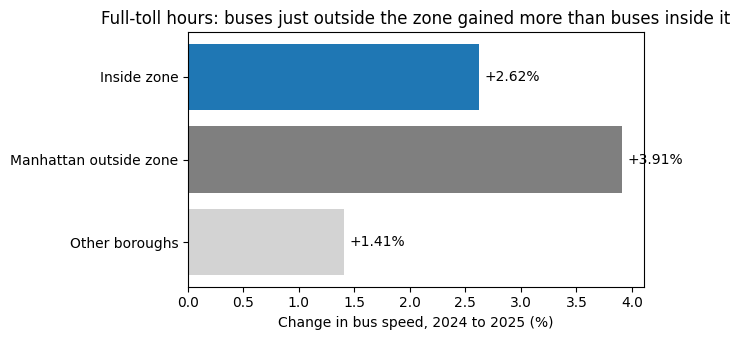

In [63]:
plt.figure(figsize=(7, 3.5))
colours = ["tab:blue", "tab:gray", "lightgray"]
plt.barh(area_table["area"], area_table["speed_change_%"], color=colours)
for i, value in enumerate(area_table["speed_change_%"]):
    plt.text(value + 0.05, i, f"+{value:.2f}%", va="center")
plt.gca().invert_yaxis()                    # first area at the top
plt.xlabel("Change in bus speed, 2024 to 2025 (%)")
plt.title("Full-toll hours: buses just outside the zone gained more than buses inside it")
plt.tight_layout()
plt.savefig("fig4_Full-toll.png", dpi=300, bbox_inches="tight")
plt.show()


**The main comparison.** We compare the zone with the **other boroughs** only. Manhattan just outside the zone is not used as the comparison group, because it may itself have been affected by the toll (for example, through drivers changing their routes).

The **gap** = change inside the zone-change in the other boroughs. A positive gap means buses inside the zone improved more.

In [64]:
#The gap = change inside the zone − change in the other boroughs. A positive gap means buses inside the zone improved more

inside_rows = matched_rows[matched_rows["area"] == "Inside zone"]
other_rows = matched_rows[matched_rows["area"] == "Other boroughs"]

#Speed change in each group
change_inside = speed_change(inside_rows)
change_other = speed_change(other_rows)

#Gap= change inside the zone minus change in the other boroughs
gap_q1 = change_inside - change_other

print(f"Change inside the zone:   {change_inside:+.2f}%")
print(f"Change in other boroughs: {change_other:+.2f}%")
print(f"Gap: {gap_q1:+.2f} percentage points")

Change inside the zone:   +2.58%
Change in other boroughs: +1.29%
Gap: +1.29 percentage points


In [65]:
#Gap in Full Toll hours
gap_full = speed_change(inside_rows[inside_rows["full_toll"] == 1]) - speed_change(other_rows[other_rows["full_toll"] == 1])

#Gap in Low Toll hours
gap_low = speed_change(inside_rows[inside_rows["full_toll"] == 0]) - speed_change(other_rows[other_rows["full_toll"] == 0])

#If toll had an influence in speed gain, the full-toll gap should be bigger
gap_difference = gap_full - gap_low

toll_table = pd.DataFrame({ "comparison": ["Gap in full-toll hours", "Gap in low-toll hours", "Difference (full minus low)"],
    "percentage_points": [gap_full, gap_low, gap_difference],}).round(2)
toll_table

,comparison,percentage_points
0,Gap in full-toll hours,1.21
1,Gap in low-toll hours,1.59
2,Difference (full minus low),-0.39


In [66]:
print(matched_rows.columns.tolist())

['Route ID', 'Direction', 'Timepoint Stop ID', 'Next Timepoint Stop ID', 'Month', 'Day of Week', 'Hour of Day', 'area', 'full_toll', 'Route Type', 'Average Road Speed_2024', 'Bus Trip Count_2024', 'Average Road Speed_2025', 'Bus Trip Count_2025', 'average', 'speed_weight_2024', 'speed_weight_2025', 'percentage_change']


**Part C2. Speed change for different bus type**

The same comparison (inside the zone vs other boroughs), for each type of bus route.

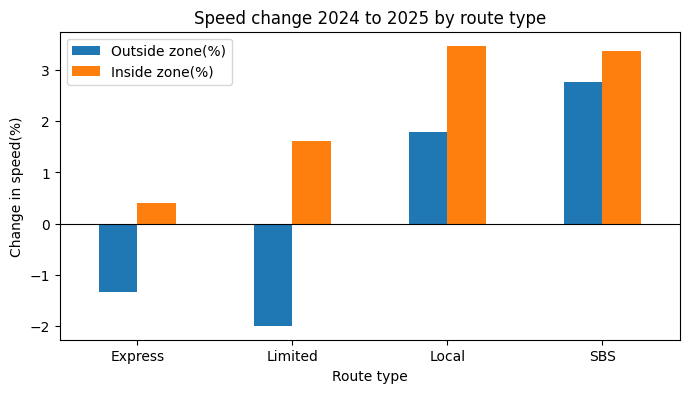

,Outside zone(%),Inside zone(%)
Route Type,,
Express,-1.34,0.40
Limited,-2.00,1.62
Local,1.79,3.48
SBS,2.77,3.37


In [67]:
matched_rows = matched_rows[matched_rows["area"].isin(["Inside zone", "Other boroughs"])].copy()
matched_rows["inside_zone"] = (matched_rows["area"] == "Inside zone").astype(int)

#Weighted speeds for each year
matched_rows["speed_2024_average"] = matched_rows["Average Road Speed_2024"]*matched_rows["average"]
matched_rows["speed_2025_average"] = matched_rows["Average Road Speed_2025"]*matched_rows["average"]

#Total avergae speeds for each route type, inside and outside the zone
type_totals = matched_rows.groupby(["Route Type", "inside_zone"])[["speed_2024_average","speed_2025_average"]].sum()

#Percentage change in speed from 2024 to 2025
type_totals["change%"] = (type_totals["speed_2025_average"]-type_totals["speed_2024_average"])/type_totals["speed_2024_average"]*100

#Table with route types
by_type = type_totals["change%"].unstack().round(2)
by_type.columns = ["Outside zone(%)","Inside zone(%)"]

#Bar chart
by_type.plot(kind="bar", figsize=(8,4))
plt.axhline(0, color="black",linewidth=0.8)
plt.title("Speed change 2024 to 2025 by route type")
plt.ylabel("Change in speed(%)")
plt.xlabel("Route type")
plt.xticks(rotation=0)
plt.savefig("fig4_Speedchange2024to2025byroutetype.png", dpi=300, bbox_inches="tight")
plt.show()

by_type

#**Part D: Machine Learning prediction of slow segments**
**Part D: RQ2, predicting slow segments**

D1. Testing a month the model has never seen

D2. Feature selection by input group

D3. Testing a month the model has never seen

D4. Cross-validation by route

D5. Factors making the bus segment slow

Target: slow =1 if the segment speed is the slowest 25% of all rows

Input: time, segment, zone,pricing flags, route type, borough

In [68]:

#The threshold is the speed that the slowest quarter (25%) of segment-hours fall below
print(f"25th percentile of bus speed: {ny_bus["Average Road Speed"].quantile(0.25):.2f} mph")
#Other cut-offs for comparison - 10%,25%(used),50%(median)
for share in [0.10, 0.25, 0.50]:
  print(f"Slowest {share:.0%} of segment-hours are below {ny_bus["Average Road Speed"].quantile(share):.2f} mph")

slow_threshold = ny_bus["Average Road Speed"].quantile(0.25)
ny_bus["slow"] = (ny_bus['Average Road Speed']<slow_threshold).astype(int)
print(f"A segment counts as slow below {slow_threshold:.2f}mph which is below New York's 6.5 mph average local bus speed (NYC Comptroller)")
print(ny_bus["slow"].value_counts())

#Class balance check. About 1 in 4 rows is slow, a clear minority with plenty of examples to learn from
print("\n Rows labelled slow:", ny_bus["slow"].sum(), f"({ny_bus["slow"].mean():.0%} of all rows)")


25th percentile of bus speed: 6.21 mph
Slowest 10% of segment-hours are below 5.04 mph
Slowest 25% of segment-hours are below 6.21 mph
Slowest 50% of segment-hours are below 7.94 mph
A segment counts as slow below 6.21mph which is below New York's 6.5 mph average local bus speed (NYC Comptroller)
slow
0    1888036
1     629346
Name: count, dtype: int64

 Rows labelled slow: 629346 (25% of all rows)


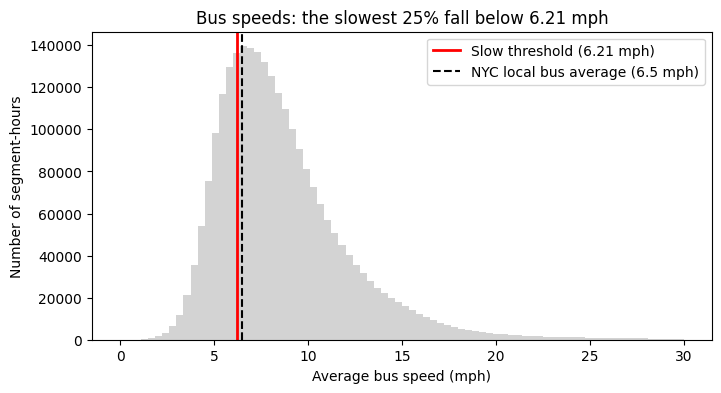

In [69]:
#chart the threshold in the speed distribution
plt.figure(figsize=(8, 4))
plt.hist(ny_bus["Average Road Speed"], bins=80, range=(0, 30), color="lightgray")
plt.axvline(slow_threshold, color="red", linewidth=2, label=f"Slow threshold ({slow_threshold:.2f} mph)")
plt.axvline(6.5, color="black", linestyle="--", label="NYC local bus average (6.5 mph)")
plt.xlabel("Average bus speed (mph)")
plt.ylabel("Number of segment-hours")
plt.title("Bus speeds: the slowest 25% fall below 6.21 mph")
plt.legend()
plt.show()

In [70]:
input_columns = ["Hour of Day", "weekend", "Month", "Road Distance", "Bus Trip Count",
                 "mid_lat", "mid_lon", "inside_zone", "after", "inside_after",
                 "Route Type", "Borough"]
#Route type and borough are text, turned into 0/1 columns (one-hot encoding)
X = pd.get_dummies(ny_bus[input_columns], columns=["Route Type", "Borough"], dtype=int)
y= ny_bus["slow"]
feature_names = X.columns.tolist()
print("Number of inputs:", len(feature_names))
feature_names


Number of inputs: 20


['Hour of Day',
 'weekend',
 'Month',
 'Road Distance',
 'Bus Trip Count',
 'mid_lat',
 'mid_lon',
 'inside_zone',
 'after',
 'inside_after',
 'Route Type_Express',
 'Route Type_Limited',
 'Route Type_Local',
 'Route Type_SBS',
 'Borough_Bronx',
 'Borough_Brooklyn',
 'Borough_Manhattan',
 'Borough_Other',
 'Borough_Queens',
 'Borough_Staten Island']

**Part D1. Predicting a month the model has never seen**

The model learns from Oct 2024-November 2025 and tested on dec 2025.
To keep training fast, the models learn from a random sample of 300,000 rows. The test month is not sampled: every test row is used.

In [71]:
# Rows used for TESTING: December 2025 (hidden from the models during training)
test_rows =(ny_bus["Year"] == 2025) & (ny_bus["Month"] ==12)

# Training data: every row NOT in the test month
X_train_all, y_train_all = X[~test_rows], y[~test_rows]

# Test data: only the rows in the test month (December 2025)
X_test, y_test = X[test_rows], y[test_rows]

# 300,000 random training rows to keep training fast (random_state=42 gives the same rows every run)
X_train = X_train_all.sample(300_000,random_state=42)

# Get the matching answers (slow or not) for exactly those sampled rows, using their row index
y_train = y_train_all.loc[X_train.index]

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 300000
Test rows: 422611


In [72]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

#Logistic Regression needs input on the same scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train_scaled, y_train)
print("Logistic Regression Trained")


Logistic Regression Trained


In [73]:
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
print("Decision Tree trained")


Decision Tree trained


In [74]:
forest = RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
print("Random Forest trained")

Random Forest trained


**Metrics**
- **Accuracy:** share of correct predictions.
- **ROC-AUC:** how well the model ranks slow segments above fast ones. 0.5 = guessing, 1.0 = perfect.
- **F1:** balances catching slow segments with not raising false alarms.

A model gives a chance of being slow; above 50% (0.5) counts as "slow"

In [75]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, average_precision_score

# Step 1: each model gives every test row a chance (0 to 1) of being slow
# predict_proba returns two columns: [chance of "not slow", chance of "slow"]
prob_log_reg = log_reg.predict_proba(X_test_scaled)[:,1]
prob_tree = tree.predict_proba(X_test)[:,1]
prob_forest = forest.predict_proba(X_test)[:,1]

# Step 2: turn each chance into a yes/no prediction
# If the chance is above 50%, predict "slow" (True); otherwise "not slow" (False)
pred_log_reg = prob_log_reg > 0.5
pred_tree = prob_tree > 0.5
pred_forest = prob_forest > 0.5

#Baseline
baseline_accuracy = 1 - y_test.mean()
# Step 2: build the results table one model at a time
rows = []

rows.append({"model": "Baseline (always 'not slow')",
             "accuracy": baseline_accuracy,
             "ROC_AUC": 0.5, "PR_AUC": y_test.mean(), "F1": 0.0})
for name, probs, preds in [("Logistic Regression", prob_log_reg, pred_log_reg),
                           ("Decision Tree", prob_tree, pred_tree),
                           ("Random Forest", prob_forest, pred_forest)]:
     rows.append({"model":name,
             "accuracy": accuracy_score(y_test, preds),
             "ROC_AUC": roc_auc_score(y_test, probs),
             "PR_AUC": average_precision_score(y_test, probs),
             "F1": f1_score(y_test, preds)})

results_A = pd.DataFrame(rows).round(3)
results_A

,model,accuracy,ROC_AUC,PR_AUC,F1
0,Baseline (always 'not slow'),0.772,0.500,0.228,0.000
1,Logistic Regression,0.795,0.812,0.528,0.413
2,Decision Tree,0.801,0.794,0.487,0.387
3,Random Forest,0.880,0.937,0.817,0.717


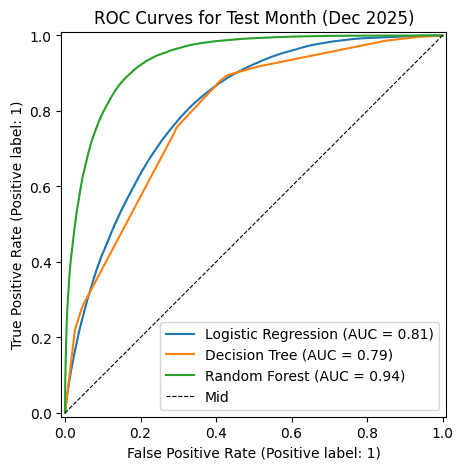

In [76]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6,5))
RocCurveDisplay.from_predictions(y_test, prob_log_reg, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_tree, name="Decision Tree", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_forest, name="Random Forest", ax=ax)
ax.plot([0,1],[0,1],"k--",linewidth=0.8,label="Mid")
ax.set_title("ROC Curves for Test Month (Dec 2025)")
ax.legend()
plt.savefig("fig5_ROC.png", dpi=300, bbox_inches="tight")
plt.show()


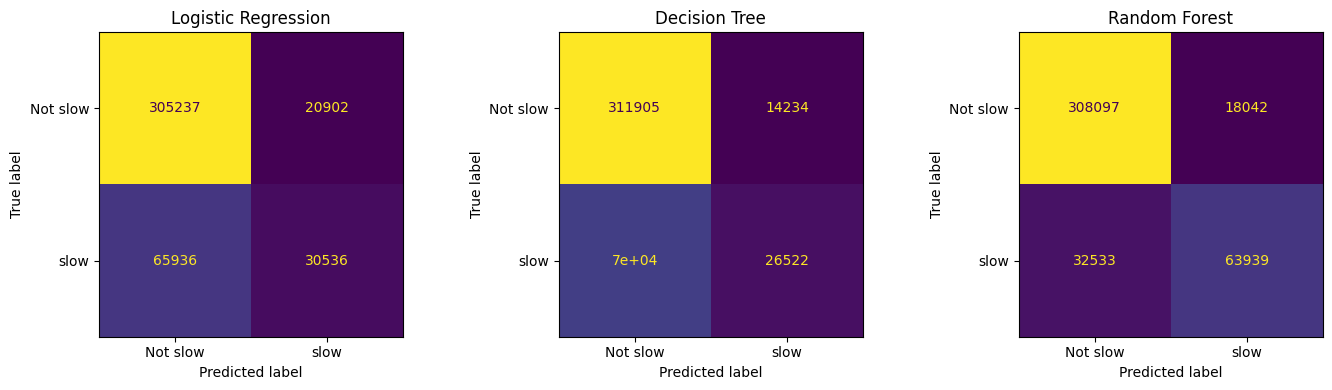

In [77]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, probs, name in zip(axes, [prob_log_reg, prob_tree, prob_forest],
                          ["Logistic Regression", "Decision Tree", "Random Forest"]):
  ConfusionMatrixDisplay.from_predictions(y_test, probs > 0.5, ax=ax, colorbar=False, display_labels=["Not slow", "slow"])
  ax.set_title(name)
plt.tight_layout()
plt.savefig("fig6_ConfusionMatrix.png", dpi=300, bbox_inches="tight")
plt.show()


**Part D2. Feature selection by input group**
Using the best model (Random Forest), we remove one group of inputs at a time, retrain, and check how much performance drops. A big drop means the group carries important information; no drop means the model doesn't need it. (This method is also known as an **ablation study**.)

**Group**     
*   **Time** - Hour of day, weekend, month
*   **Location** - mid_lat, mid_lon, borough
*   **Segment** - road distance, bus trip count, route type
*   **Zone/pricing** - inside_zone, after, inside_after








In [78]:
# The four groups of inputs to be tested
input_groups = {
    "Time": ["Hour of Day", "weekend", "Month"],
    "Location": ["mid_lat", "mid_lon"] + [c for c in feature_names if c.startswith("Borough_")],
    "Segment": ["Road Distance", "Bus Trip Count"] + [c for c in feature_names if c.startswith("Route Type_")],
    "Zone/pricing": ["inside_zone", "after", "inside_after"],
}

# Start the results table with the full model (all inputs), trained earlier
results_rows = []
results_rows.append({"inputs used": "All Inputs",
                  "ROC_AUC": roc_auc_score(y_test, prob_forest),
                  "F1": f1_score(y_test, prob_forest > 0.5)})

# Remove one group at a time, retrain, and score
for group, removed in input_groups.items():
  # Step 1: list the inputs to keep
  retained_inputs = []
  for column in feature_names:
    if column not in removed:
      retained_inputs.append(column)
  print(f"Without {group}: using {len(retained_inputs)} of {len(feature_names)} inputs")
  # Step 2: train a new Random Forest using only the retained inputs
  model = RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42)
  model.fit(X_train[retained_inputs], y_train)

  # Step 3: predict the test month and score it
  probs = model.predict_proba(X_test[retained_inputs])[:,1]
  results_rows.append({"inputs used": "Without "+ group,
                        "ROC_AUC": roc_auc_score(y_test, probs),
                        "F1": f1_score(y_test, probs > 0.5)})
# Step 4: build the table and show how much performance dropped for each group
feature_selection = pd.DataFrame(results_rows)
feature_selection["AUC_drop"] = feature_selection.loc[0, "ROC_AUC"] - feature_selection["ROC_AUC"]
feature_selection = feature_selection.round(3)
feature_selection


Without Time: using 17 of 20 inputs
Without Location: using 12 of 20 inputs
Without Segment: using 14 of 20 inputs
Without Zone/pricing: using 17 of 20 inputs


,inputs used,ROC_AUC,F1,AUC_drop
0,All Inputs,0.937,0.717,0.000
1,Without Time,0.909,0.646,0.028
2,Without Location,0.850,0.486,0.087
3,Without Segment,0.919,0.662,0.018
4,Without Zone/pricing,0.940,0.731,-0.003


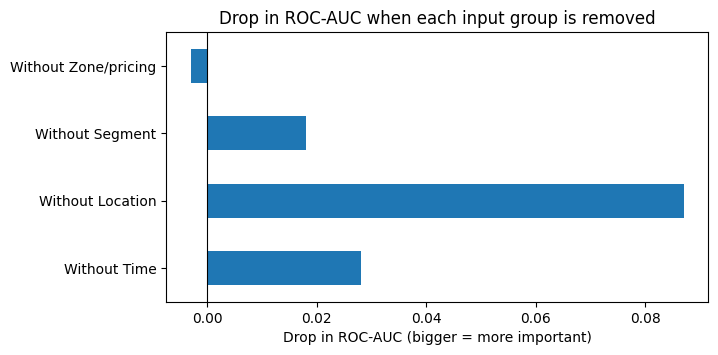

In [79]:
feature_selection.iloc[1:].plot(kind="barh", x="inputs used", y="AUC_drop", legend=False, figsize=(7,3.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Drop in ROC-AUC when each input group is removed")
plt.xlabel("Drop in ROC-AUC (bigger = more important)")
plt.ylabel("")

plt.savefig("fig7_Drop_ROC.png", dpi=300, bbox_inches="tight")
plt.show()

**Reading the result:** **location** matters most: location of a segment, explains slowness better than anything else. Time and segment features also help. Removing the **zone/pricing** inputs makes no difference: the location inputs already capture the zone, and pricing barely changed which segments are slow. This agrees with RQ1.

**Part D3. Testing on routes the model has never seen**

20% of routes are hidden during training, and the model must predict them from scratch to check if the model has learned general patterns, not memorised particular routes.

In [80]:
#Step 1: pick 20% of routes to hide
rng = np.random.default_rng(42)          # fixed seed, so the same routes are picked every run
all_routes = ny_bus["Route ID"].unique()             # list of every route
number_to_hide = int(len(all_routes) * 0.2)          # 20% of routes
hidden_routes = rng.choice(all_routes, size=number_to_hide, replace=False)   # pick them at random

# Rows used for TESTING: every row on a hidden route
test_rows_hidden = ny_bus["Route ID"].isin(hidden_routes)

# Training data: every row NOT on a hidden route
X_train_all_hidden, y_train_all_hidden = X[~test_rows_hidden], y[~test_rows_hidden]

# Test data: only the rows on the hidden route
X_test_hidden, y_test_hidden = X[test_rows_hidden], y[test_rows_hidden]

# 300,000 random training rows to keep training fast (random_state=42 gives the same rows every run)
X_train_hidden = X_train_all_hidden.sample(300_000,random_state=42)

# Get the matching answers (slow or not) for exactly those sampled rows, using their row index
y_train_hidden = y_train_all_hidden.loc[X_train_hidden.index]

print("Total routes: ", len(all_routes))
print("Hidden routes: ", len(hidden_routes))
print("Training rows:", len(X_train_hidden))
print("Test rows:", len(X_test_hidden))

#Step 3: train the three models
scaler_hidden = StandardScaler()
X_train_hidden_scaled = scaler_hidden.fit_transform(X_train_hidden)
X_test_hidden_scaled = scaler_hidden.transform(X_test_hidden)

log_reg_hidden = LogisticRegression(max_iter=2000)
log_reg_hidden.fit(X_train_hidden_scaled, y_train_hidden)

tree_hidden = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_hidden.fit(X_train_hidden, y_train_hidden)

forest_hidden = RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=20,
                                  n_jobs=-1, random_state=42)
forest_hidden.fit(X_train_hidden, y_train_hidden)


#Step 4: predict the hidden routes (chance of being slow)
prob_log_reg_hidden = log_reg_hidden.predict_proba(X_test_hidden_scaled)[:, 1]
prob_tree_hidden = tree_hidden.predict_proba(X_test_hidden)[:, 1]
prob_forest_hidden = forest_hidden.predict_proba(X_test_hidden)[:, 1]

#Step 5: build the results table (one row per model)
rows = []
rows.append({"model": "Baseline (always 'not slow')", "accuracy": 1 - y_test_hidden.mean(),
             "ROC_AUC": 0.5, "PR_AUC": y_test_hidden.mean(), "F1": 0.0})

for name, probs in [("Logistic Regression", prob_log_reg_hidden), ("Decision Tree", prob_tree_hidden), ("Random Forest", prob_forest_hidden)]:
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test_hidden, probs > 0.5),
                 "ROC_AUC": roc_auc_score(y_test_hidden, probs),
                 "PR_AUC": average_precision_score(y_test_hidden, probs),
                 "F1": f1_score(y_test_hidden, probs > 0.5)})

results_B = pd.DataFrame(rows).round(3)
results_B


Total routes:  373
Hidden routes:  74
Training rows: 300000
Test rows: 433578


,model,accuracy,ROC_AUC,PR_AUC,F1
0,Baseline (always 'not slow'),0.764,0.500,0.236,0.000
1,Logistic Regression,0.788,0.800,0.518,0.430
2,Decision Tree,0.782,0.757,0.444,0.299
3,Random Forest,0.839,0.894,0.693,0.612


**Part D4. Cross validation by route**

We shuffle the bus routes and split them into **5 groups**. Each time, the models learn from 4 groups and are tested on the 5th, whose routes they have **never seen**. Every route is tested exactly once.
We split by **route**, not by random rows, because the same stretch of road appears many times (different hours, days and months). Random splits would put almost identical rows in both training and testing, making the models look better than they really are.

In [81]:
#Step 1: take a random sample to keep it fast
cv_data = ny_bus.sample(300_000, random_state = 42)
X_cv = X.loc[cv_data.index]
y_cv = y.loc[cv_data.index]

#Step 2: shuffle the routes and split them into 5 groups
rng = np.random.default_rng(42)
all_routes = np.array(cv_data["Route ID"]. unique(), dtype=str)
rng.shuffle(all_routes)
route_groups = np.array_split(all_routes,5)

cv_rows = [] # results of every round are saved here

#Step 3: 5 rounds; each round tests on one group of routes
for fold_number in range(5):
  test_routes = route_groups[fold_number]
  is_test = cv_data["Route ID"].isin(test_routes)
  is_train = is_test == False
# Split the inputs and answers into training and test parts
  X_tr = X_cv[is_train]
  y_tr = y_cv[is_train]
  X_te = X_cv[is_test]
  y_te = y_cv[is_test]
  #Logistic Regression - scale the inputs first
  scaler = StandardScaler()
  X_tr_scaled = scaler.fit_transform(X_tr)
  X_te_scaled = scaler.transform(X_te)

  log_reg_cv = LogisticRegression(max_iter = 2000)
  log_reg_cv.fit(X_tr_scaled, y_tr)
  prob_lr = log_reg_cv.predict_proba(X_te_scaled)[:,1]

  #Decision Tree
  tree_cv = DecisionTreeClassifier(max_depth=4, random_state=42)
  tree_cv.fit(X_tr,y_tr)
  prob_dt = tree_cv.predict_proba(X_te)[:,1]

  #Random Forest
  forest_cv = RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=20,n_jobs=-1, random_state=42)
  forest_cv.fit(X_tr,y_tr)
  prob_rf = forest_cv.predict_proba(X_te)[:,1]

  #Scores for each model
  cv_rows.append({"model": "Logistic Regression", "fold": fold_number + 1,
                    "ROC_AUC": roc_auc_score(y_te, prob_lr), "F1": f1_score(y_te, prob_lr > 0.5)})
  cv_rows.append({"model": "Decision Tree", "fold": fold_number + 1,
                    "ROC_AUC": roc_auc_score(y_te, prob_dt), "F1": f1_score(y_te, prob_dt > 0.5)})
  cv_rows.append({"model": "Random Forest", "fold": fold_number + 1,
                    "ROC_AUC": roc_auc_score(y_te, prob_rf), "F1": f1_score(y_te, prob_rf > 0.5)})
  print("Round", fold_number + 1, "of 5 done")

#Step 4: summarise the 5 rounds
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model")[["ROC_AUC", "F1"]].agg(["mean", "std"]).round(3)
cv_summary

Round 1 of 5 done
Round 2 of 5 done
Round 3 of 5 done
Round 4 of 5 done
Round 5 of 5 done


ROC_AUC            F1       
                       mean    std   mean    std
model                                           
Decision Tree         0.777  0.015  0.378  0.057
Logistic Regression   0.805  0.020  0.439  0.070
Random Forest         0.895  0.010  0.635  0.043

**Part D5.Causes of bus segment being slow**




**Logistic Regression Coefficients**

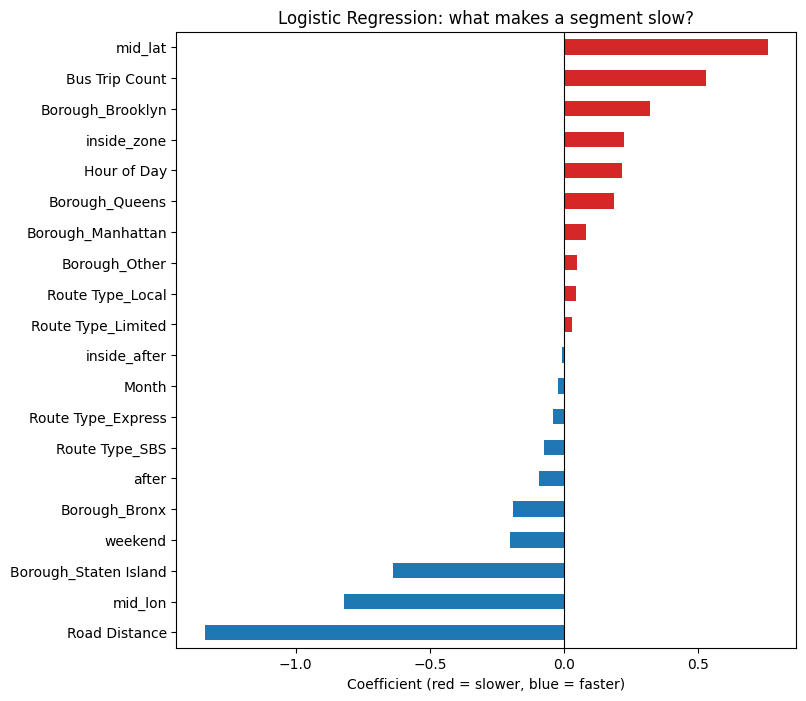

Effect of congestion pricing inside the zone (inside_after): -0.007


In [82]:
# Get the coefficient (weight) the Logistic Regression learned for each input,
# label each one with its input name, and sort from most negative to most positive
coeff = pd.Series(log_reg.coef_[0], index=feature_names).sort_values()

# Horizontal bar chart: blue bars (negative) lower the chance of being slow, red bars (positive) raise it
coeff.plot(kind="barh", figsize=(8,8), color=["tab:blue" if c<0 else "tab:red" for c in coeff])
plt.axvline(0,color="black", linewidth=0.8)
plt.title("Logistic Regression: what makes a segment slow?")
plt.xlabel("Coefficient (red = slower, blue = faster)")
plt.savefig("fig_logReg_coeff.png", dpi=300, bbox_inches="tight")
plt.show()

# The pricing effect inside the zone: close to 0 means pricing barely changed the chance of being slow
print("Effect of congestion pricing inside the zone (inside_after):", round(coeff["inside_after"], 3))

Logistic regression uses standardized inputs. A positive coefficient raises the chance of a segment being slow, and a negative one lowers it. Longer segments were much less likely to be slow (coefficient −1.34), because they have fewer stops and signals per mile. Segments further north (+0.76), busier segments (+0.53) and segments inside the zone (+0.22) were more likely to be slow, while the zone-and-pricing interaction was essentially zero (−0.007)

**Decision Tree Rules.**
Read from the top. Each box asks a yes/no question; orange boxes lean towards slow.


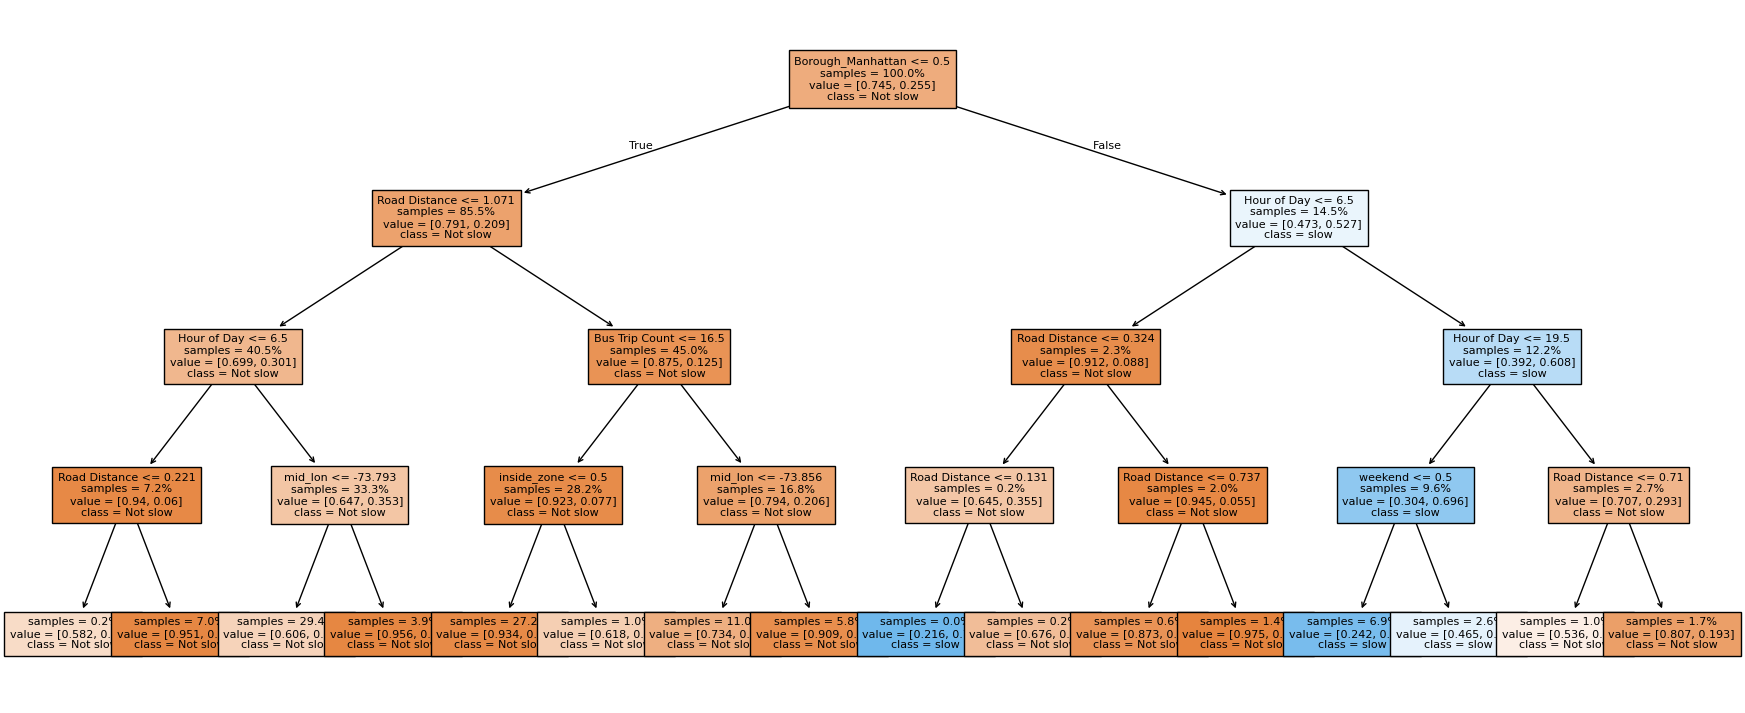

In [83]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22,9))
plot_tree(tree, feature_names=feature_names, class_names=["Not slow", "slow"], filled=True, fontsize =8 , impurity=False, proportion = True)
plt.savefig("fig_DT_rules.png", dpi=300, bbox_inches="tight")
plt.show()

The decision tree’s depth-4 tree gives readable rules. Its first split separates Manhattan routes from all others, showing that location is the main divide. For routes outside Manhattan, it splits next on segment length (about 1.07 miles), then on hour of day or number of buses. For Manhattan routes, it splits next on hour of day; early morning (6 a.m. or earlier) is separated from the rest of the day, and evening (8 p.m. onwards) from daytime. The tree therefore matches the other models. Slowness depends mainly on where a segment is, how long it is and the time of day.

**Random Forest Importance.** How much the forest relies on each input.

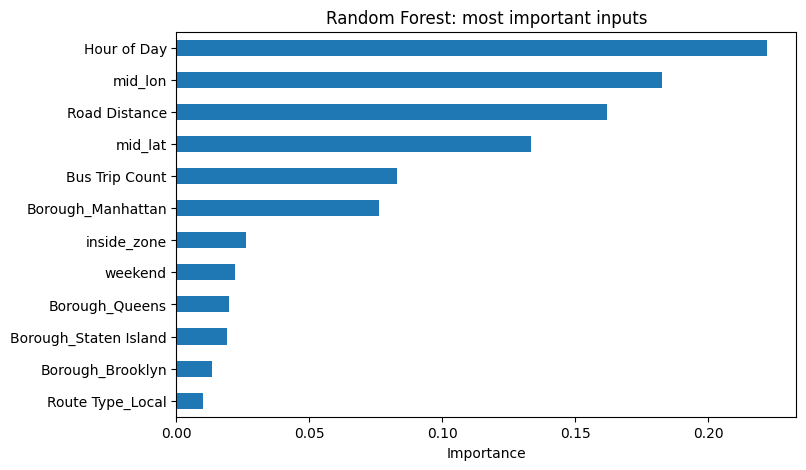

In [84]:
imp = pd.Series(forest.feature_importances_, index=feature_names).sort_values().tail(12)

imp.plot(kind="barh", figsize=(8,5))
plt.title("Random Forest: most important inputs")
plt.xlabel("Importance")
plt.savefig("figRF_Importance.png", dpi=300, bbox_inches="tight")
plt.show()

Random forest’s feature importance measures how much each input helps the forest’s trees separate slow from not-slow segments. Time of day and location (longitude and latitude) dominate, followed by segment length. The zone inputs contribute little. The random forest relied most on hour of day (importance 0.222), longitude (0.183), segment length (0.162) and latitude (0.133).

#**Part E. Bus Priority Need Segment List**

The slowest segments in weekday rush hours (7-9am and 4-7pm) in 2025, used by at least 10 buses an hour. These are the highest candidates for bus lanes, signal priority and camera enforcement.

In [85]:
rush = ny_bus[(ny_bus["weekend"]==0) & (ny_bus["Hour of Day"].isin([7,8,16,17,18])) & (ny_bus["after"] ==1)]
priority = rush.groupby(["Route ID", "Timepoint Stop Name", "Next Timepoint Stop Name", "inside_zone"]).agg(
    avg_speed_mph=("Average Road Speed", "mean"), buses_per_hour=("Bus Trip Count", "mean"),).reset_index()

priority = priority[priority["buses_per_hour"] >= 10]
priority = priority.sort_values("avg_speed_mph").head(15).round(2)
priority

,Route ID,Timepoint Stop Name,Next Timepoint Stop Name,inside_zone,avg_speed_mph,buses_per_hour
1513,M103,LEXINGTON AV/E 100 ST,LEXINGTON AV/E 96 ST,0,2.56,14.79
1481,M101,LEXINGTON AV/E 100 ST,LEXINGTON AV/E 96 ST,0,2.65,19.26
2146,Q27,MAIN ST/39 AV,MAIN ST/39 AV,0,2.85,46.56
1473,M101,3 AV/E 97 ST,3 AV/E 99 ST,0,2.87,20.76
1496,M102,LEXINGTON AV/E 100 ST,LEXINGTON AV/E 96 ST,0,2.99,17.95
1872,M96,W 96 ST/BROADWAY,W 96 ST/WEST END AV,0,3.10,53.51
1537,M106,W 96 ST/BROADWAY,W 96 ST/WEST END AV,0,3.24,13.76
1840,M79+,W 79 ST/RIVERSIDE DR,W 79 ST/BROADWAY,0,3.30,41.47
1582,M125,E 125 ST/3 AV,E 125 ST/MADISON AV,0,3.32,32.32
1752,M42,W 42 ST/7 AV,W 42 ST/8 AV,1,3.35,36.25


#**Conclusions and limitations**

**RQ1 The toll has no real effect on bus speeds**
1. Bus speeds rose across the city between October–December 2024 and 2025 (+1.55% overall).
2. Buses inside the zone improved slightly more than buses in the other boroughs (+2.55% vs +1.26%; gap +1.30 points)
3. But buses in Manhattan just **outside** the zone improved **even more** during full-toll hours (+3.72%, vs +2.60% inside the zone), even though nobody pays the toll there.
4. The gain was **no bigger in full-toll hours**, when the toll is four times higher (gap +1.23 vs +1.56 points in low-toll hours; difference −0.33)
5. So the pattern looks like a **Manhattan-wide improvement**, not a toll effect. Likely explanations include drivers changing routes around the zone and bus-lane camera enforcement, which expanded in 2025.
6. Local, Limited and Express buses inside the zone improved more than the same route types in the other boroughs; SBS routes, which already have bus priority, improved strongly in both.

**RQ2: Can machine learning find the slow spots? Yes.**

7. The Random Forest predicts slow segments far better than the baseline and the simpler models: ROC-AUC **0.937** on an unseen month,ROC-AUC **0.894** on unseen routes and **0.895 ± 0.010** in cross-validation by route.
8. **Location matters most**, followed by time of day and segment length. Removing the zone/pricing inputs changes nothing, which agrees with RQ1.
10. **Priority list:** the slowest busy segments are mostly **outside** the zone, around East and West 96th–100th Street, so pricing alone doesn't reach the worst bottlenecks.